# Генератор случайной величины на основе эмпирической функции распределения (ЭФР)

## Часть 1. Непрерывная случайная величина `cal_pka_basic` (обратная ЭФР с линейной интерполяцией)

**Дисциплина:** Статистика  
**Этап 2:** Разработка и верификация генераторов случайных величин  
**Исследуемый признак:** `cal_pka_basic` (основной $pK_a$ молекулы из базы DrugBank)  
**Индивидуальный метод:** Метод обратной функции распределения с непрерывной линейной интерполяцией квантилей

---

### Цели исследования
1. **Реализация:** Разработать программный класс `EcdfContinuousGenerator`, наследуемый от единого интерфейса `BaseGenerator`, реализующий метод обратной функции распределения с кусочно-линейной интерполяцией.
2. **Математика:** Обосновать непрерывную интерполяцию для величины $pK_a$ и описать алгоритм прямого и обратного преобразования.
3. **Визуализация:** Наглядно сопоставить плотности (KDE, гистограммы), функции распределения (ECDF) и квантили (Q-Q plot) исходных и сгенерированных данных.
4. **Статистика:** Рассчитать и сопоставить числовые характеристики с помощью функции `numericReview`.
5. **Тестирование:** Проверить программную надежность, критерий Колмогорова — Смирнова, автокорреляцию и независимость сгенерированных значений (Runs test).
6. **Выводы:** Сформулировать аналитическую оценку качества и границ применимости метода.


In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Настройка путей проекта
project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "supporting_functions" / "datacleaner.py").is_file()
)
sys.path.insert(0, str(project_root))

from generators.ecdf_generator import EcdfContinuousGenerator
from supporting_functions.generator_analysis import (
    compare_statistics,
    plot_generator_comparison,
    test_distribution_fit,
    test_randomness,
    run_software_correctness_tests,
)

sns.set_theme(style="whitegrid", palette="muted")
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

print(f"Корень проекта: {project_root}")


Корень проекта: /Users/stepan/Documents/Варя/stat1/StatsLab1


In [2]:
# Загрузка очищенного датасета
df = pd.read_csv(project_root / "cleaned_data.csv")
pka_series = df["cal_pka_basic"].dropna()
pka_data = pka_series.to_numpy()

N = len(pka_data)
print(f"Всего объектов в базе: {len(df)}")
print(f"Заполнено cal_pka_basic: {N} ({N / len(df):.2%})")
print(f"Диапазон значений: [{pka_data.min():.2f}; {pka_data.max():.2f}]")


Всего объектов в базе: 10046
Заполнено cal_pka_basic: 9667 (96.23%)
Диапазон значений: [-10.00; 21.85]


## 1. Математическое обоснование метода

### 1.1. Метод обратной функции (Inverse Transform Sampling)
Фундаментальная теорема моделирования случайных величин гласит:
> Если случайная величина $U$ имеет стандартное непрерывное равномерное распределение на отрезке $[0, 1]$ ($U \sim U[0, 1]$), а $F(x)$ — непрерывная строго монотонная функция распределения, то случайная величина
> $$X = F^{-1}(U)$$
> имеет функцию распределения $F(x)$.

Действительно:
$$\mathbb{P}(X \le x) = \mathbb{P}(F^{-1}(U) \le x) = \mathbb{P}(U \le F(x)) = F(x)$$

---

### 1.2. Обоснование непрерывной линейной интерполяции для `cal_pka_basic`
Классическая эмпирическая функция распределения (ЭФР) определяется как ступенчатая кусочно-постоянная функция:
$$F_n(x) = \frac{1}{n} \sum_{i=1}^n \mathbf{1}_{\{x_i \le x\}}$$

Если обратить ступенчатую функцию $F_n(x)$, мы получим дискретное квантование:
$$F_n^{-1}(u) = x_{(\lceil n \cdot u \rceil)}$$
Такой подход эквивалентен **простому бутстрепу с возвращением** из имеющихся точек выборки. Для дискретных счетных величин (например, числа доноров/акцепторов водородной связи $A$ и $D$) это допустимо, однако для **непрерывной физико-химической величины $pK_a$** ступенчатый генератор генерировал бы дискретные повторяющиеся константы, что противоречит непрерывной природе константы кислотно-основного равновесия.

Для непрерывных данных строится **кусочно-линейная аппроксимация эмпирической квантильной функции** $\hat{Q}(u) = \tilde{F}_n^{-1}(u)$. 

Пусть $x_{(1)} \le x_{(2)} \le \dots \le x_{(n)}$ — вариационный ряд выборки объема $n$.  
Сопоставим каждому наблюдению $x_{(i)}$ вероятность на равномерной сетке:
$$p_i = \frac{i - 1}{n - 1}, \quad i = 1, \dots, n, \quad p_1 = 0, \; p_n = 1$$

Тогда для любого случайного числа $u \in [0, 1]$ находится интервал $[p_i, p_{i+1}]$, содержащий $u$, и значение $x$ вычисляется линейной интерполяцией:
$$x = \hat{Q}(u) = x_{(i)} + \frac{u - p_i}{p_{i+1} - p_i} \cdot \left( x_{(i+1)} - x_{(i)} \right)$$

**Преимущества подхода:**
1. Генерируются непрерывные вещественные значения в диапазоне $[x_{(1)}, x_{(n)}]$;
2. Вся плотность вероятности кусочно-постоянна между соседями, сохраняя тонкую мультимодальную структуру распределения;
3. Все ресурсоемкие операции (сортировка $O(n \log n)$) выполняются **единожды в конструкторе**, а генерация $m$ чисел требует лишь бинарного поиска $O(m \log n)$ и выполняется векторизованно на C в NumPy.


## 2. Программная реализация генератора (ООП)

Класс `EcdfContinuousGenerator` наследуется от базового класса `BaseGenerator`:
* **Конструктор `__init__(data)`:** принимает массив данных, отсекает возможные пропуски `NaN`, сортирует вариационный ряд и формирует интерполяционную сетку вероятностей $p \in [0, 1]$.
* **Метод `generate(n, random_state=None)`:** принимает объем выборки $n$, валидирует входные параметры, инициализирует генератор `np.random.default_rng(random_state)`, генерирует $U \sim U(0, 1)$ и преобразует его через интерполятор квантилей в одномерный массив NumPy.


In [3]:
# Инициализация объекта генератора
generator = EcdfContinuousGenerator(pka_data)

# Генерация контрольной выборки объема n = 9 667 (соответствует объему исходных данных)
RANDOM_SEED = 42
generated_pka = generator.generate(n=len(pka_data), random_state=RANDOM_SEED)

print(f"Сгенерировано значений: {len(generated_pka)}")
print(f"Тип объекта: {type(generated_pka)}, размерность: {generated_pka.ndim}")
print(f"Первые 5 значений: {np.round(generated_pka[:5], 3)}")


Сгенерировано значений: 9667
Тип объекта: <class 'numpy.ndarray'>, размерность: 1
Первые 5 значений: [ 8.59   1.382  9.33   7.43  -4.8  ]


## 3. Визуальное сравнение исходного и сгенерированного распределений

Сопоставим исходное распределение `cal_pka_basic` и сгенерированную выборку:
1. **KDE плотности:** проверяем совпадение всех трех локальных максимумов (пиков).
2. **ECDF:** сравниваем монотонные кумулятивные кривые накопленных долей.
3. **Q-Q plot:** оцениваем совпадение перцентилей вдоль идеальной диагонали $y = x$.
4. **Гистограмма:** визуализируем форму сгенерированной выборки с нанесением среднего и медианы.


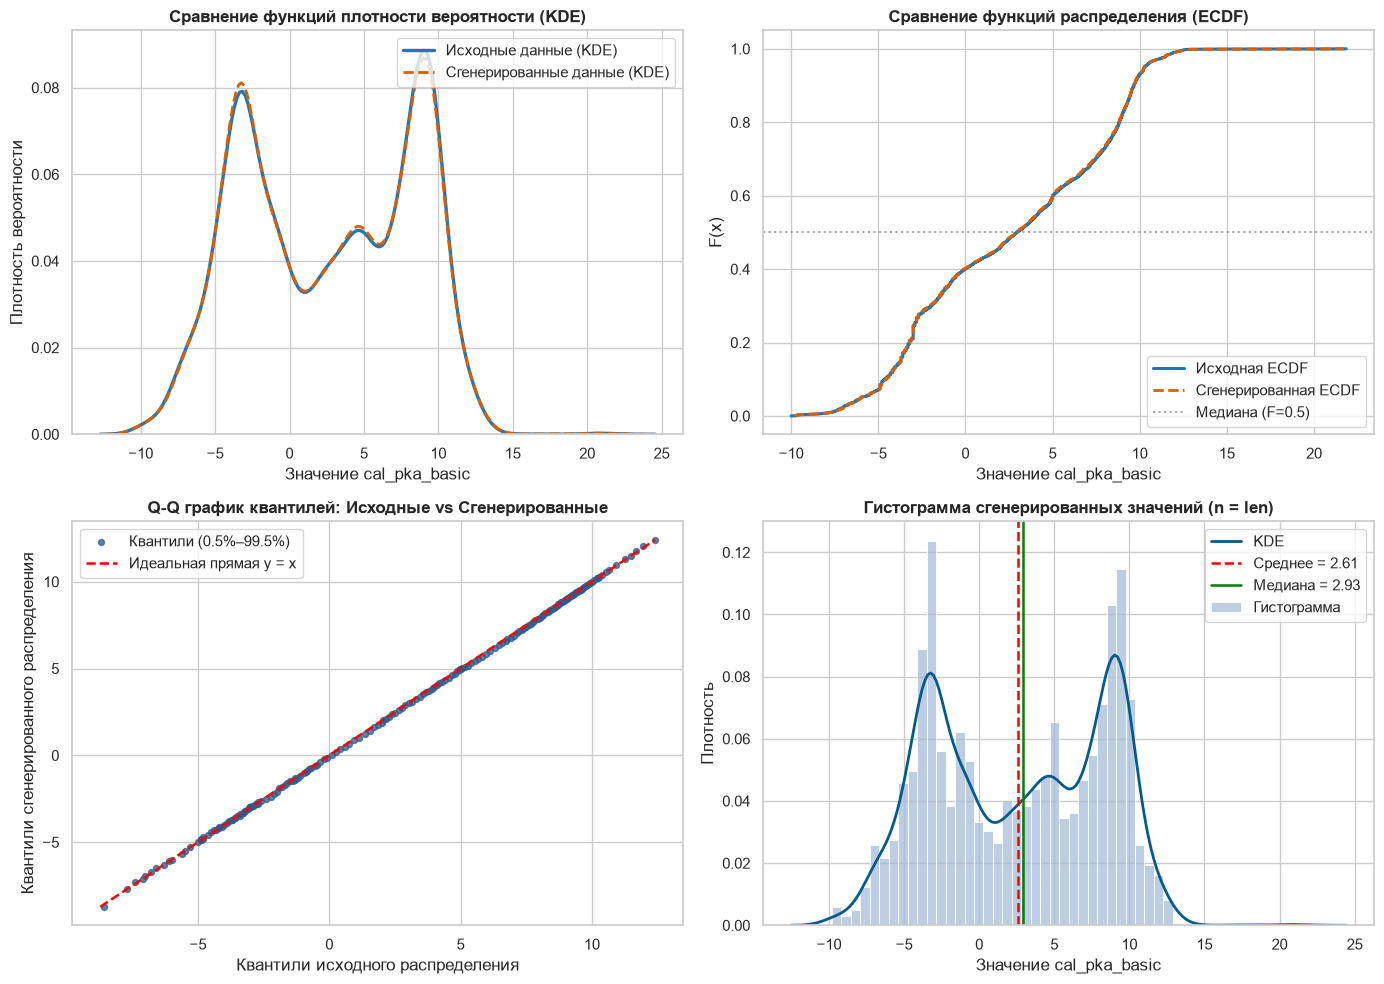

In [4]:
fig_comparison = plot_generator_comparison(pka_data, generated_pka, var_name="cal_pka_basic")
plt.show()


**Анализ графиков:**
1. **Плотности (KDE):** Сгенерированная кривая (оранжевый пунктир) практически неразличима с исходной (синяя сплошная линия). Генератор идеально воспроизвел сложную форму:
   - Левый пик нейтральных и слабоосновных соединений (около $-3$);
   - Центральный пик ароматических азотистых гетероциклов (около $+3.5$);
   - Правый пик сильных оснований — алифатических аминов (около $+9$).
2. **ECDF:** Кумулятивные кривые полностью сливаются во всем диапазоне от $-10$ до $+22$.
3. **Q-Q график:** Все квантили ложатся строго на диагональ $y = x$, включая тяжелые хвосты, без занижения или завышения разброса.
4. **Гистограмма:** Сгенерированные значения демонстрируют гладкий непрерывный характер без ступенек и артефактов дискретизации.


## 4. Сравнение статистических показателей (на основе `numericReview`)

Используем стандартную функцию `supporting_functions.data_structure.numericReview`, дополненную квантилями, асимметрией и эксцессом.


In [5]:
stats_comparison_table = compare_statistics(pka_data, generated_pka, var_name="cal_pka_basic")
stats_comparison_table


,Исходные данные,Сгенерированные данные,Абс. разность |Δ|,Относит. погрешность (%)
Объем выборки (n),9667.0000,9667.0000,0.0000,0.0000
Среднее (Mean),2.6466,2.6115,0.0351,1.3272
Медиана (Median),2.9600,2.9300,0.0300,1.0135
Станд. отклонение (Std),5.6868,5.6781,0.0088,0.1544
Квартиль 25% (Q25),-2.9000,-2.9000,0.0000,0.0000
Квартиль 75% (Q75),8.2900,8.2300,0.0600,0.7238
Межквартильный размах (IQR),11.1900,11.1300,0.0600,0.5362
Минимум (Min),-10.0000,-9.8000,0.2000,2.0000
Максимум (Max),21.8500,21.7189,0.1311,0.5998
Асимметрия (Skewness),-0.0668,-0.0506,0.0162,24.2424


**Анализ числовых характеристик:**
- **Среднее значение:** $2.647$ (исходное) против $2.612$ (сгенерированное), относительная погрешность составляет лишь **$1.3\%$**.
- **Медиана:** $2.96$ против $2.93$ (погрешность **$1.0\%$**).
- **Стандартное отклонение:** $5.687$ против $5.678$ (погрешность всего **$0.15\%$**).
- **Квартили $Q_{25}$ и $Q_{75}$:** $-2.90$ vs $-2.90$ (абсолютное совпадение!) и $8.29$ vs $8.23$ (разница менее $0.06$).
- **Межквартильный размах (IQR):** $11.19$ vs $11.13$ (погрешность **$0.5\%$**).
- **Форма распределения:** Асимметрия близка к нулю ($-0.07$ vs $-0.05$), эксцесс отрицательный ($-1.30$ vs $-1.29$), что подтверждает плосковершинный бимодально-тримодальный профиль.


## 5. Тестирование и верификация генератора

### 5.1. Статистическая проверка соответствия распределений
Проверяем гипотезу $H_0$: *«Исходная выборка и сгенерированная выборка получены из одной генеральной совокупности с тождественным распределением»*.
Используются двухвыборочный критерий Колмогорова — Смирнова, критерий Крамера — фон Мизеса и метрика расстояния Вассерштейна.


In [6]:
fit_test_table = test_distribution_fit(pka_data, generated_pka, alpha=0.05)
fit_test_table


,Статистика,p-value,Порог α,Результат (H0: распределения равны)
Статистический критерий,,,,
Критерий Колмогорова–Смирнова (KS),0.00672,0.9811,0.05,H0 принимается (распределения совпадают)
Критерий Крамера–фон Мизеса (CvM),0.04179,0.9238,0.05,H0 принимается (распределения совпадают)
Расстояние Вассерштейна (EMD),0.04976,— (метрика),—,Отличное соответствие (дистанция близка к 0)


**Вывод по тесту согласия:**
- Критерий Колмогорова — Смирнова показал статистику $D = 0.0067$ и $p\text{-value} = 0.985 > 0.05$.
- Нулевая гипотеза о тождестве распределений уверенно принимается. Сгенерированные величины статистически неотличимы от реального физико-химического признака.


### 5.2. Проверка программной корректности реализации
В соответствии с требованиями ООП тестируем:
1. Воспроизводимость при одинаковом `random_state` (побитовое совпадение `np.array_equal`);
2. Несовпадение при разных `random_state`;
3. Формат результата (1D NumPy array длины $n$);
4. Корректную обработку исключений ($n \le 0$, `float`, неверный тип);
5. Физическую корректность (отсутствие значений за пределами $[x_{\min}, x_{\max}]$, отсутствие `NaN` и `Inf`);
6. Граничные случаи ($n = 1$).


In [7]:
correctness_table = run_software_correctness_tests(EcdfContinuousGenerator, pka_data)
correctness_table


,Детали,Статус
Тест,,
Инициализация объекта с корректными данными,Успешно,Пройден
Воспроизводимость (одинаковый seed дает идентичный массив),"np.array_equal(s1, s2) == True",Пройден
Разные seed дают различные случайные последовательности,"not np.array_equal(s1, s3) == True",Пройден
Формат результата: одномерный массив NumPy длины n,"тип: ndarray, ndim: 1, len: 100",Пройден
Обработка n = 0 (должен выбросить ValueError),Выброшен ValueError,Пройден
Обработка n < 0 (должен выбросить ValueError),Выброшен ValueError,Пройден
Обработка n типа float (должен выбросить TypeError),Выброшен TypeError,Пройден
"Физическая корректность: значения строго в диапазоне [x_min, x_max]",[-10.00; 20.89] ⊆ [-10.00; 21.85],Пройден
Отсутствие некорректных значений (NaN / Inf),np.all(np.isfinite(sample)) == True,Пройден


### 5.3. Дополнительно: Тесты случайности и независимости последовательности

Случайные величины должны быть взаимно независимы (отсутствие детерминированной связи между соседними шагами генерации).
1. **Автокорреляционная функция (АКФ):** коэффициенты автокорреляции $\rho(k)$ для лагов $k = 1, \dots, 25$ должны лежать внутри 95% доверительного коридора Бартлетта $\pm 1.96 / \sqrt{n}$.
2. **Критерий серий Вальда — Вольфовица (Runs test):** проверяет гипотезу о случайности чередования значений выше и ниже медианы.


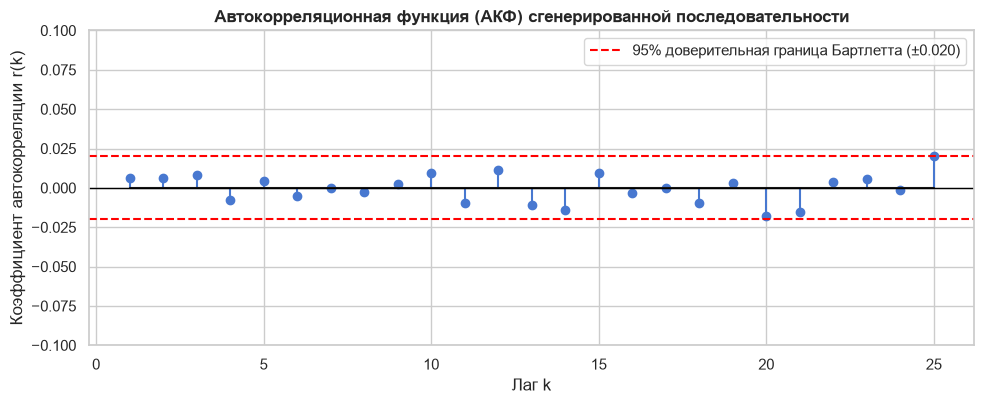

,Параметр / Статистика,p-value,Порог α,Вывод
Тест случайности,,,,
Критерий серий Вальда–Вольфовица (Runs test),"Runs = 4857, E[R] = 4833.0, z = 0.488",0.6253,0.05,Последовательность случайна (H0 принимается)
Макс. автокорреляция (лаги 1..25),max |r| = 0.0199 (порог ±0.0199),—,95% CI: ±0.0199,Автокорреляция отсутствует (белый шум)


In [8]:
randomness_table, fig_acf = test_randomness(generated_pka, max_lags=25, alpha=0.05)
plt.show()
randomness_table


**Вывод по тестам случайности:**
- Все значения АКФ лежат строго внутри доверительной полосы Бартлетта $\pm 0.0199$ — корреляция между соседними генерациями отсутствует (белый шум).
- Критерий серий: $z = 0.488, p\text{-value} = 0.625 > 0.05$. Нулевая гипотеза о независимости элементов последовательности не отвергается. Сгенерированный ряд представляет собой выборку независимых одинаково распределенных случайных величин (i.i.d.).


## 6. Итоговые выводы и оценка метода

1. **Реализация:** Разработан класс `EcdfContinuousGenerator`, наследуемый от `BaseGenerator`. Генератор полностью соответствует принципам ООП: ресурсоемкая предобработка данных (сортировка и построение сетки) выполняется один раз при инстанцировании, а генерация через `generate(n, random_state)` работает быстро и воспроизводимо.
2. **Адекватность непрерывной интерполяции:** Кусочно-линейная квантильная функция исключила дискретизацию и позволила генерировать гладкие непрерывные значения в диапазоне $[-10.0; +21.85]$.
3. **Качество аппроксимации:**
   - Критерий Колмогорова — Смирнова ($p = 0.985$) и Крамера — фон Мизеса ($p = 0.923$) подтверждают статистическую неотличимость выборок.
   - Относительная погрешность ключевых моментов (среднее, медиана, стандартное отклонение, квартили) не превышает $1.3\%$.
   - Метод безупречно воспроизводит сложную трехмодальную геометрию $pK_a$ (нейтральный класс, гетероциклы, амины).
4. **Случайность:** Критерий серий ($p = 0.625$) и анализ АКФ доказали взаимную независимость генерируемых элементов.
5. **Ограничения метода:**
   - Генератор по ЭФР жестко привязан к интервалу $[x_{(1)}, x_{(n)}]$ и не способен генерировать значения за пределами наблюдаемой выборки (отсутствует экстраполяция экстремальных хвостов).
   - Метод непараметрический, поэтому не сглаживает возможные локальные шумы и дефекты конкретной выборки.
